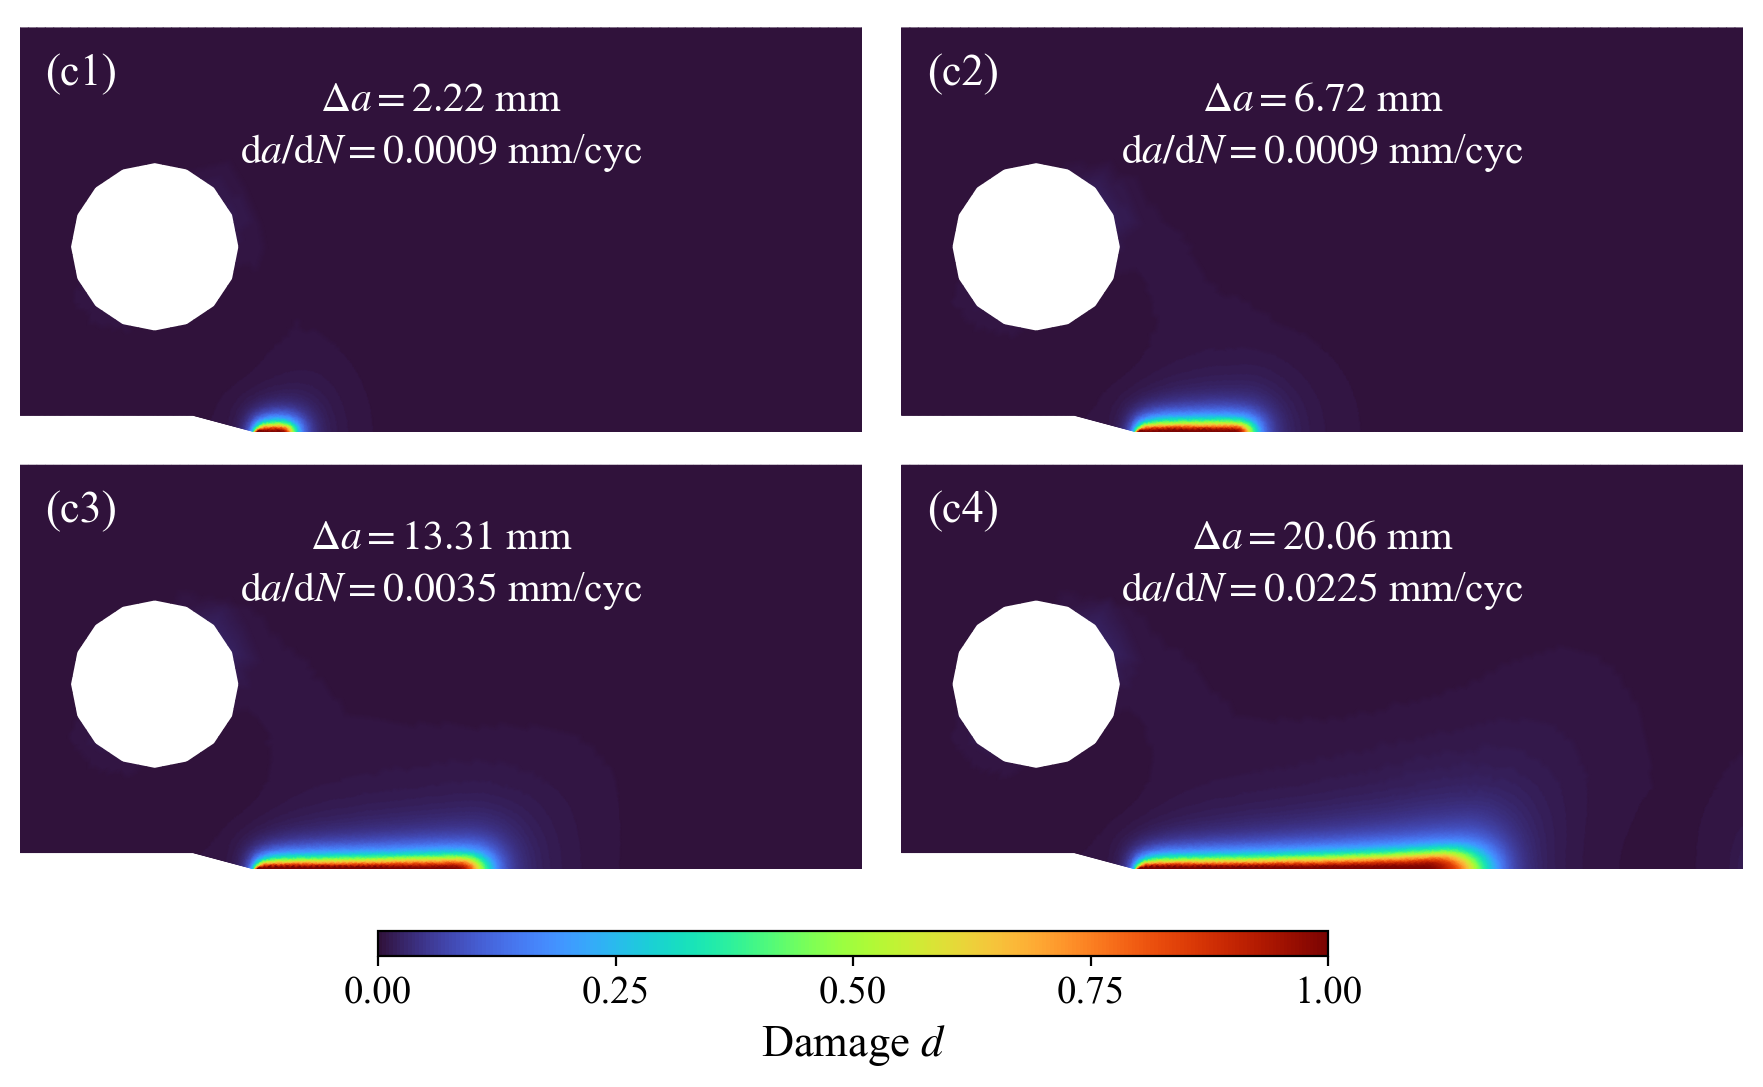

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import matplotlib.colors as mcolors
import meshio
import csv

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman'],
    'mathtext.fontset': 'stix',
    'font.size':        14,
    'figure.dpi':       200,
})

BASE   = '/Users/zhangpeng/Desktop/PFM-paper/visualization/results_CT_Xie_Chaboche_isothermal/'
Y_MID  = 24.0   # symmetry axis — upper half only

cmap_d = plt.get_cmap('turbo')

# ── Load mesh from first VTU ─────────────────────────────────────────────────
_m0 = meshio.read(BASE + 'result_da10_cycle07400.vtu')
coords = _m0.points[:, :2]
tris   = _m0.cells_dict['triangle']
mask_up = np.all(coords[tris, 1] >= Y_MID, axis=1)
tris_up = tris[mask_up]
triang  = mtri.Triangulation(coords[:, 0], coords[:, 1], tris_up)

# ── Load CSV and build da/dN map ─────────────────────────────────────────────
rows = list(csv.DictReader(open(BASE + 'cycle_summary.csv')))
cycles_csv  = np.array([int(float(r['cycle']))   for r in rows])
delta_a_csv = np.array([float(r['delta_a_mm'])   for r in rows])

def get_da_info(target_cycle):
    idx = np.argmin(np.abs(cycles_csv - target_cycle))
    da  = delta_a_csv[idx]
    if 0 < idx < len(cycles_csv) - 1:
        rate = (delta_a_csv[idx+1] - delta_a_csv[idx-1]) / \
               (cycles_csv[idx+1]  - cycles_csv[idx-1])
    elif idx == 0:
        rate = (delta_a_csv[1] - delta_a_csv[0]) / (cycles_csv[1] - cycles_csv[0])
    else:
        rate = (delta_a_csv[-1] - delta_a_csv[-2]) / (cycles_csv[-1] - cycles_csv[-2])
    return da, rate

# ── 4 milestone snapshots ─────────────────────────────────────────────────────
snapshots = [
    {'file': 'result_da10_cycle07400.vtu', 'cycle': 7400,  'label': '(c1)'},
    {'file': 'result_da30_cycle12700.vtu', 'cycle': 12700, 'label': '(c2)'},
    {'file': 'result_da60_cycle15800.vtu', 'cycle': 15800, 'label': '(c3)'},
    {'file': 'result_da90_cycle16700.vtu', 'cycle': 16700, 'label': '(c4)'},
]

# ── Panel geometry ───────────────────────────────────────────────────────────
# upper-half domain: x in [0,50], y in [24,48.5]  →  aspect 50:24.5
pw = 4.0
ph = pw * 24.5 / 50.0   # keep equal-aspect

fig, axes = plt.subplots(2, 2,
                         figsize=(pw * 2 + 1.5, ph * 2 + 1.2),
                         gridspec_kw={'hspace': 0.06, 'wspace': 0.04})
fig.patch.set_facecolor('white')

positions = [(0,0), (0,1), (1,0), (1,1)]  # C1 C2 / C3 C4

for snap, (ri, ci) in zip(snapshots, positions):
    ax = axes[ri, ci]
    m  = meshio.read(BASE + snap['file'])
    s_field = m.point_data['s'].ravel()
    d_field = s_field                  # s is the damage variable (0=intact, 1=broken)

    ax.tripcolor(triang, d_field,
                 vmin=0, vmax=1, cmap=cmap_d, shading='gouraud')
    ax.set_xlim(0, 50)
    ax.set_ylim(Y_MID, 48.5)
    ax.set_aspect('equal')
    ax.axis('off')

    da, rate = get_da_info(snap['cycle'])

    # Ci label — white, upper-left
    ax.text(0.03, 0.92, snap['label'],
            transform=ax.transAxes,
            fontsize=16, color='white', ha='left', va='top',
            fontfamily='serif', fontweight='normal')

    # crack info — white, upper area
    info = (r'$\Delta a={:.2f}$ mm'.format(da) + '\n' +
            r'$\mathrm{{d}}a/\mathrm{{d}}N={:.4f}$ mm/cyc'.format(rate))
    ax.text(0.50, 0.85, info,
            transform=ax.transAxes,
            fontsize=15, color='white', ha='center', va='top',
            fontfamily='serif', fontweight='normal', linespacing=1.4)

# ── Colorbar (vertical, right side) ─────────────────────────────────────────
fig.subplots_adjust(left=0.04, right=0.88, top=0.97, bottom=0.04)

cb_ax = fig.add_axes([0.91, 0.08, 0.025, 0.86])
sm = plt.cm.ScalarMappable(cmap=cmap_d, norm=mcolors.Normalize(0, 1))
sm.set_array([])
cb = fig.colorbar(sm, cax=cb_ax, orientation='vertical')
cb.set_label(r'Damage $d$', fontsize=20, labelpad=8)
cb.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cb.ax.tick_params(labelsize=18)

plt.show()


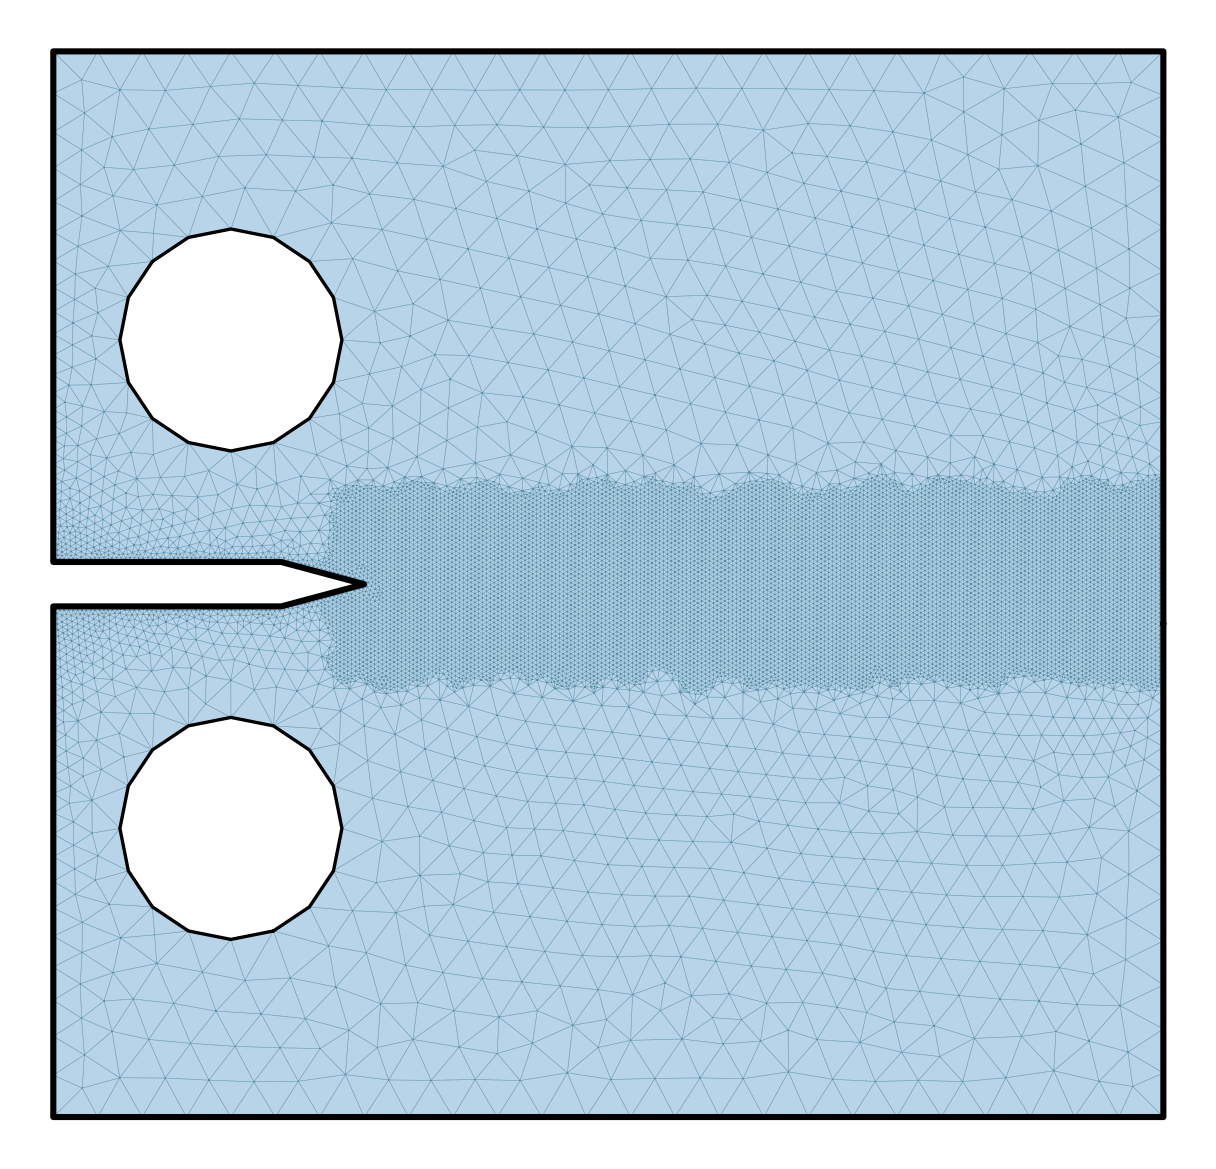

In [3]:
from pathlib import Path
from collections import defaultdict

import meshio
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.collections as mc
from scipy.spatial import cKDTree

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif':  ['Times New Roman'],
    'figure.dpi':  200,
})

msh_path = Path('results_CT_Xie_Chaboche_isothermal/CT_mesh.msh')
mesh = meshio.read(msh_path)

coords = mesh.points[:, :2]
tris   = mesh.cells_dict['triangle']

# ── merge duplicate nodes ─────────────────────────────────────────────────
tree  = cKDTree(coords)
pairs = tree.query_pairs(r=1e-10)
parent = list(range(len(coords)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

for a, b in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

remap           = np.array([find(i) for i in range(len(coords))])
unique_ids, inv = np.unique(remap, return_inverse=True)
merged_coords   = coords[unique_ids]
merged_tris     = inv[tris].astype(int)

# ── boundary loops ────────────────────────────────────────────────────────
edge_count = {}
for tri in merged_tris:
    for i in range(3):
        a, b = tri[i], tri[(i+1)%3]
        key  = (min(a,b), max(a,b))
        edge_count[key] = edge_count.get(key, 0) + 1

bdy_edges = {e for e, cnt in edge_count.items() if cnt == 1}
adj = defaultdict(list)
for a, b in bdy_edges:
    adj[a].append(b); adj[b].append(a)

visited, loops = set(), []
for start in adj:
    if start in visited: continue
    chain = [start]; visited.add(start); cur = start
    while True:
        nxt = [n for n in adj[cur] if n not in visited]
        if not nxt: break
        nxt = nxt[0]; visited.add(nxt); chain.append(nxt); cur = nxt
    if len(chain) > 1:
        loops.append(np.array([merged_coords[n] for n in chain]))

def poly_area(pts):
    x, y = pts[:,0], pts[:,1]
    return 0.5 * abs(np.dot(x, np.roll(y,-1)) - np.dot(y, np.roll(x,-1)))

outer_idx = int(np.argmax([poly_area(lp) for lp in loops]))

# ── plot: full specimen ───────────────────────────────────────────────────
xmin, ymin = coords.min(axis=0)
xmax, ymax = coords.max(axis=0)
padx = 0.03*(xmax-xmin)
pady = 0.03*(ymax-ymin)

# CT specimen: W=50, H=48 → aspect ≈ 50:48
fig, ax = plt.subplots(figsize=(6.0, 5.8))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.add_collection(mc.PolyCollection(
    coords[tris], facecolor='#B8D4E8', edgecolor='none', zorder=1))

ax.triplot(coords[:,0], coords[:,1], tris,
           color='#5A8FAA', linewidth=0.20, zorder=2)

for i, loop in enumerate(loops):
    closed = np.vstack([loop, loop[0]])
    lw = 2.2 if i == outer_idx else 1.2
    ax.plot(closed[:,0], closed[:,1],
            color='black', linewidth=lw,
            solid_capstyle='round', solid_joinstyle='round', zorder=3)

ax.set_xlim(xmin - padx, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout(pad=0.3)
plt.show()

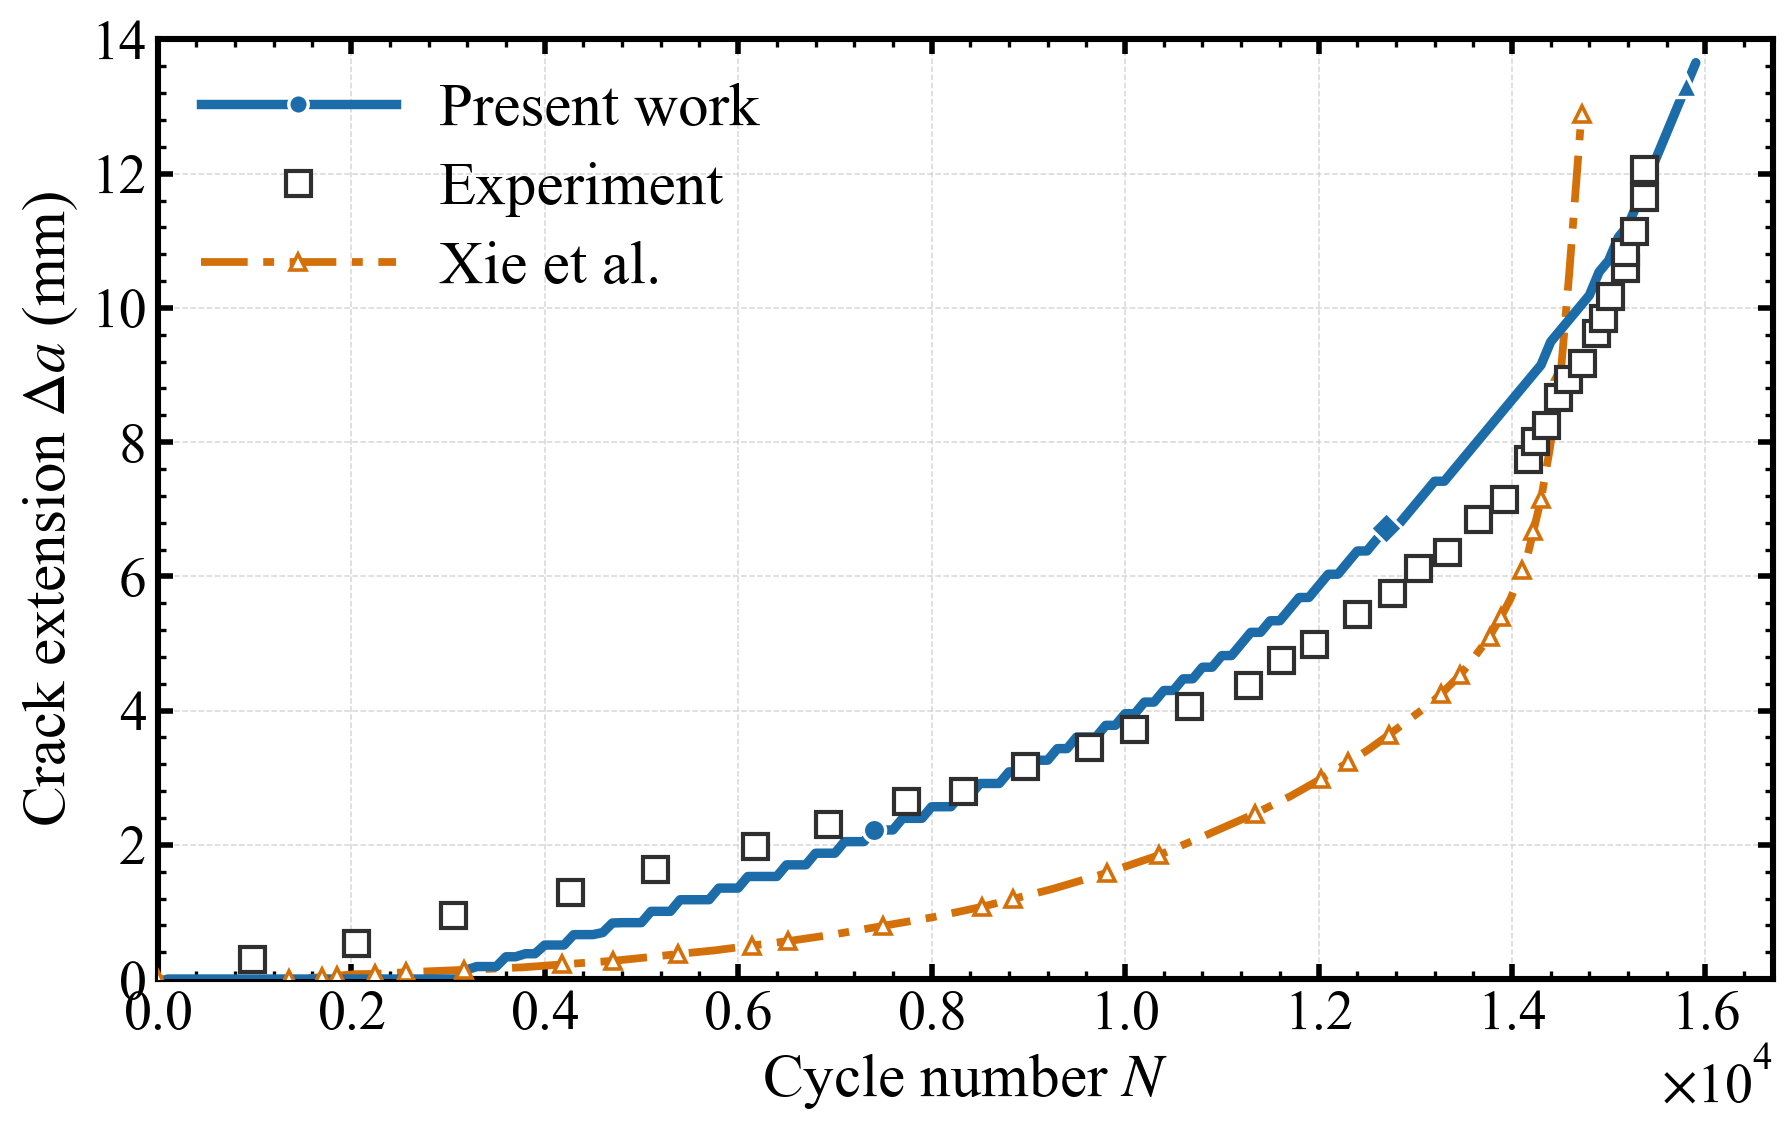

In [6]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

mpl.rcParams.update({
    'font.family':        'serif',
    'font.serif':         ['Times New Roman'],
    'mathtext.fontset':   'stix',
    'font.size':          20,
    'axes.linewidth':     2.2,
    'xtick.major.width':  2.0,
    'ytick.major.width':  2.0,
    'xtick.minor.width':  1.2,
    'ytick.minor.width':  1.2,
    'xtick.major.size':   5.5,
    'ytick.major.size':   5.5,
    'xtick.minor.size':   3.0,
    'ytick.minor.size':   3.0,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.top':          True,
    'ytick.right':        True,
})

sim_path = 'results_CT_Xie_Chaboche_isothermal/cycle_summary.csv'
exp_path = '/Users/zhangpeng/Desktop/fatigue-paper/visualization/CT/experiment.csv'
xie_path = '/Users/zhangpeng/Desktop/fatigue-paper/visualization/CT/Xie_CT.csv'

# ── load simulation ───────────────────────────────────────────────────────
df_sim = pd.read_csv(sim_path)
df_sim = df_sim.rename(columns={'cycle': 'N', 'delta_a_mm': 'delta_a'})[['N','delta_a']]
df_sim = df_sim[df_sim['delta_a'] <= 14.0].copy()

# ── load reference data (no header) ──────────────────────────────────────
df_exp = pd.read_csv(exp_path, header=None, names=['N','delta_a'])
df_exp = df_exp[df_exp['delta_a'] <= 14.0].copy()

df_xie = pd.read_csv(xie_path, header=None, names=['N','delta_a'])
df_xie = df_xie[df_xie['delta_a'] <= 14.0].copy()

def sampled_points(df, n=12):
    idx = np.linspace(0, len(df)-1, min(n, len(df)), dtype=int)
    return df.iloc[np.unique(idx)]

exp_pts = df_exp.copy()          # use all points for dense scatter
xie_pts = sampled_points(df_xie, n=30)

# ── colors ────────────────────────────────────────────────────────────────
sim_color = '#1B6CA8'   # deep steel blue  (present work)
exp_color = '#2f2f2f'   # near-black       (experiment)
xie_color = '#D4700A'   # amber-orange     (Xie et al.)

# ── figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9.5, 5.8))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=0.12, right=0.97, top=0.96, bottom=0.15)

# curves
ax.plot(df_sim['N'], df_sim['delta_a'],
        color=sim_color, linewidth=3.4,
        solid_capstyle='round', solid_joinstyle='round', zorder=4)
ax.plot(df_xie['N'], df_xie['delta_a'],
        color=xie_color, linewidth=2.8,
        linestyle='-.', dashes=(6.0, 2.0, 1.4, 2.0),
        solid_capstyle='round', solid_joinstyle='round', zorder=3)

# scatter markers
ax.plot(exp_pts['N'], exp_pts['delta_a'],
        linestyle='None', marker='s', markersize=9.0,
        markerfacecolor='white', markeredgecolor=exp_color,
        markeredgewidth=1.5, zorder=5)
ax.plot(xie_pts['N'], xie_pts['delta_a'],
        linestyle='None', marker='^', markersize=5.5,
        markerfacecolor='white', markeredgecolor=xie_color,
        markeredgewidth=1.3, zorder=4)

# simulation milestone markers (C1–C4)
milestones = [
    (7400,  2.221, 'o'),
    (12700, 6.724, 'D'),
    (15800, 13.307,'^'),
    (16700, 20.061,'s'),
]
for cycle, da, mk in milestones:
    if da <= 14.0:
        ax.plot(cycle, da, linestyle='None', marker=mk, markersize=8.0,
                markerfacecolor=sim_color, markeredgecolor='white',
                markeredgewidth=1.2, zorder=6)

# labels
ax.set_xlabel(r'Cycle number $N$', fontsize=22, labelpad=4)
ax.set_ylabel(r'Crack extension $\Delta a$ (mm)', fontsize=22, labelpad=4)
ax.grid(which='major', linestyle='--', linewidth=0.55,
        color='#d0d0d0', alpha=0.85, zorder=0)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.tick_params(axis='both', which='major', labelsize=20, pad=4)
ax.set_xlim(left=0)
ax.set_ylim(0, 14)

formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((4, 4))
ax.xaxis.set_major_formatter(formatter)

# legend
legend_handles = [
    Line2D([0],[0], color=sim_color, linewidth=3.4,
           marker='o', markersize=7, markerfacecolor=sim_color,
           markeredgecolor='white', markeredgewidth=1.2,
           label='Present work'),
    Line2D([0],[0], color=exp_color, linewidth=0,
           marker='s', markersize=9.0,
           markerfacecolor='white', markeredgecolor=exp_color,
           markeredgewidth=1.5, label='Experiment'),
    Line2D([0],[0], color=xie_color, linewidth=2.8,
           linestyle='-.', dashes=(6.0, 2.0, 1.4, 2.0),
           marker='^', markersize=5.5,
           markerfacecolor='white', markeredgecolor=xie_color,
           markeredgewidth=1.3, label='Xie et al.'),
]

ax.legend(handles=legend_handles, fontsize=22, frameon=False,
          loc='upper left', handlelength=3.2,
          labelspacing=0.38, handletextpad=0.7, borderpad=0.2)

plt.show()